# 📧 Email Spam Classification Using a Single-Layer Perceptron
### Course: 21CSE326T - Artificial Neural Networks
**Implementation from Scratch**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com)

---

## Project Overview
In this notebook, we demonstrate the design, implementation, training, evaluation, and limitations of a **Single-Layer Perceptron (SLP)** built strictly from scratch without high-level ML frameworks (no PyTorch, TensorFlow, or scikit-learn).

### Table of Contents:
1. **Mathematical Foundations & Scratch Implementation** (`Perceptron`, Pocket Algorithm, Metrics, Logistic Regression Baseline)
2. **Part 1: 5-Feature Synthetic Email Spam Classifier** (Feature extraction, interactive classification, adversarial evasion, and 2D decision boundary visualization)
3. **Part 2: Linear Separability Limitation** (The classic XOR problem and Minsky-Papert bottleneck)
4. **Part 3: Official UCI Spambase Dataset (57 features)** (Automated download/loading, z-score standardization, training, confusion matrix, ROC/AUC curve, and top feature weights)
5. **Summary & Key Takeaways**


## 1. Setup & Dependencies
We only rely on standard Python libraries: `numpy` for linear algebra, `matplotlib` for charts, and `urllib` to automatically fetch the dataset if running in Google Colab or a fresh environment.


In [1]:
import os
import re
import urllib.request
import numpy as np
import matplotlib.pyplot as plt

# Styling for plots
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11

print(f"NumPy version: {np.__version__}")


NumPy version: 2.3.3


## 2. Mathematical Foundation & Scratch Perceptron Model

### The Perceptron Formulation (Frank Rosenblatt, 1958)
For an input vector $\mathbf{x} = [x_1, x_2, \dots, x_n]^T \in \mathbb{R}^n$, weights $\mathbf{w} = [w_1, w_2, \dots, w_n]^T$, and scalar bias $b$:

1. **Net Input / Weighted Sum ($z$)**:
   $$z = \mathbf{w} \cdot \mathbf{x} + b = \sum_{i=1}^n w_i x_i + b$$

2. **Step Activation Function (Heaviside Step)**:
   $$\hat{y} = \text{step}(z) = \begin{cases} 1 & \text{if } z \ge 0 \quad (\text{Spam}) \\ 0 & \text{if } z < 0 \quad (\text{Legitimate/Ham}) \end{cases}$$

3. **Perceptron Learning Rule**:
   Given target $t \in \{0, 1\}$ and prediction $\hat{y} \in \{0, 1\}$, the error is $e = t - \hat{y}$:
   $$\mathbf{w} \leftarrow \mathbf{w} + \eta \cdot (t - \hat{y}) \cdot \mathbf{x}$$
   $$b \leftarrow b + \eta \cdot (t - \hat{y})$$
   where $\eta$ is the learning rate.

4. **Gallant's Pocket Algorithm**:
   Standard perceptrons can oscillate indefinitely when data is not strictly linearly separable. The **Pocket Algorithm** maintains the best weight vector encountered so far in its "pocket" and restores it after training.


In [2]:
class Perceptron:
    """Single-layer Perceptron written from scratch with NumPy."""
    def __init__(self, n, lr=0.1):
        self.w = np.zeros(n)
        self.b = 0.0
        self.lr = lr

    def z(self, X):
        """Compute net input: z = X @ w + b."""
        return X @ self.w + self.b

    def predict(self, X):
        """Heaviside step activation: 1 if z >= 0 else 0."""
        return (self.z(X) >= 0).astype(int)

    def update(self, x, t):
        """Single-sample update using Rosenblatt's learning rule."""
        y = int(x @ self.w + self.b >= 0)
        e = int(t) - y
        self.w = self.w + self.lr * e * x
        self.b += self.lr * e
        return y, e

    def fit(self, X, t, epochs=30, seed=0):
        """Train using Pocket Perceptron variant to preserve best weights."""
        rng = np.random.default_rng(seed)
        hist = []
        best = (-1, None, None)
        for ep in range(epochs):
            for i in rng.permutation(len(X)):
                self.update(X[i], t[i])
            acc = float((self.predict(X) == t).mean())
            hist.append(acc)
            if acc > best[0]:
                best = (acc, self.w.copy(), self.b)
            if acc == 1.0:
                break
        self.w, self.b = best[1], best[2]
        return hist


def metrics(t, p):
    """Compute classification performance metrics from scratch."""
    tp = int(((t == 1) & (p == 1)).sum())
    tn = int(((t == 0) & (p == 0)).sum())
    fp = int(((t == 0) & (p == 1)).sum())
    fn = int(((t == 1) & (p == 0)).sum())
    pr = tp / max(tp + fp, 1)
    rc = tp / max(tp + fn, 1)
    acc = (tp + tn) / len(t)
    f1 = 2 * pr * rc / max(pr + rc, 1e-9)
    return dict(tp=tp, tn=tn, fp=fp, fn=fn, accuracy=acc, precision=pr, recall=rc, f1=f1)


def logreg(X, y, it=800, lr=0.5):
    """Baseline Logistic Regression trained with batch gradient descent."""
    w = np.zeros(X.shape[1])
    b = 0.0
    for _ in range(it):
        g = 1 / (1 + np.exp(-(X @ w + b))) - y
        w -= lr * X.T @ g / len(y)
        b -= lr * g.mean()
    return w, b


## 3. Part 1: 5-Feature Synthetic Email Spam Classifier
In addition to the 57-feature UCI dataset, the project includes a transparent 5-feature email analyzer:
1. **Suspicious links count** (links, bit.ly, www)
2. **Spam keywords count** (`free`, `winner`, `prize`, `claim`, `cash`, etc.)
3. **Sender reputation** (evaluated by domain: `.edu` / `.gov` vs `.xyz` / `.biz`)
4. **Capital letters ratio** (CAPS ratio)
5. **Exclamation mark frequency** (`!`)


In [3]:
FEATURE_NAMES_5 = ["Suspicious links", "Keyword count", "Sender reputation", "CAPS ratio", "Exclamations"]
SPAM_KEYWORDS = ["free","winner","win","prize","cash","urgent","offer","click","buy","cheap","credit","loan",
                 "viagra","lottery","guarantee","bonus","claim","limited","act now","congratulations",
                 "password","verify","suspended"]
BAD_TLD = (".xyz", ".ru", ".top", ".click", ".biz", ".win")
GOOD_DOMAINS = ("gmail.com", "outlook.com", ".edu", ".edu.in", ".gov", ".ac.in", ".org")

def extract_features(text, sender=""):
    """Convert raw email text and sender into 5 normalized numeric features [0..1]."""
    t = text.lower()
    links = len(re.findall(r"https?://|www\.|bit\.ly", t))
    kw = sum(t.count(k) for k in SPAM_KEYWORDS)
    letters = [c for c in text if c.isalpha()]
    caps = sum(c.isupper() for c in letters) / max(len(letters), 1)
    rep, s = 0.5, sender.lower().strip()
    if "@" in s:
        d = s.split("@")[-1]
        rep = 0.55
        if d.endswith(GOOD_DOMAINS): rep = 0.9
        if d.endswith(BAD_TLD): rep = 0.1
        if re.search(r"\d{3,}", s) or d.count("-") > 1: rep = min(rep, 0.2)
    return np.array([min(links/5, 1), min(kw/8, 1), rep, min(caps/0.6, 1), min(text.count("!")/6, 1)])

def make_synthetic_dataset(n=2000, seed=42):
    """Generate realistic synthetic email features with overlapping distributions."""
    r = np.random.default_rng(seed)
    h = n // 2
    def gen(is_spam, count):
        if is_spam:
            l, k, rep, c, e = r.poisson(2.2, count), r.poisson(4, count), r.beta(2, 5, count), r.beta(3, 6, count), r.poisson(2.5, count)
        else:
            l, k, rep, c, e = r.poisson(0.5, count), r.poisson(1, count), r.beta(5, 2, count), r.beta(1.5, 9, count), r.poisson(0.6, count)
        return np.c_[np.minimum(l/5, 1), np.minimum(k/8, 1), rep, np.minimum(c/0.6, 1), np.minimum(e/6, 1)]
    X = np.r_[gen(False, h), gen(True, h)]
    y = np.r_[np.zeros(h), np.ones(h)].astype(int)
    p = r.permutation(n)
    X, y = X[p], y[p]
    split = int(0.8 * n)
    return X[:split], y[:split], X[split:], y[split:]

X_syn_tr, y_syn_tr, X_syn_te, y_syn_te = make_synthetic_dataset()
p5 = Perceptron(n=5, lr=0.1)
hist_syn = p5.fit(X_syn_tr, y_syn_tr, epochs=30)
syn_test_metrics = metrics(y_syn_te, p5.predict(X_syn_te))

print(f"5-Feature Model Trained!")
print(f"Test Accuracy:  {syn_test_metrics['accuracy']*100:.2f}%")
print(f"Test Precision: {syn_test_metrics['precision']*100:.2f}%")
print(f"Test Recall:    {syn_test_metrics['recall']*100:.2f}%")
print(f"Test F1-Score:  {syn_test_metrics['f1']*100:.2f}%")


5-Feature Model Trained!
Test Accuracy:  98.75%
Test Precision: 99.05%
Test Recall:    98.58%
Test F1-Score:  98.81%


### 3.1 Live Classification & Explainability
We can pass raw text and sender email to inspect individual weighted contributions $w_i x_i$:


In [4]:
sample_spam = {
    "sender": "winner-claims123@cheap-offers.xyz",
    "text": "CONGRATULATIONS!!! You are a WINNER! Claim your FREE cash prize now, click http://bit.ly/win-now . Limited offer, act now!!!"
}

sample_ham = {
    "sender": "priya@srmist.edu.in",
    "text": "Hi Kanakesh, sharing the notes for tomorrow's ANN lab. Let's meet at 10 am in the library. Thanks!"
}

for label, email in [("Spam Sample", sample_spam), ("Legit Sample", sample_ham)]:
    x = extract_features(email["text"], email["sender"])
    z = p5.z(x)
    pred = "SPAM (1)" if z >= 0 else "LEGIT (0)"
    print(f"--- {label} ---")
    print(f"Sender: {email['sender']}")
    print(f"Net score z = {z:.3f} --> Predicted: {pred}")
    for name, xi, wi in zip(FEATURE_NAMES_5, x, p5.w):
        print(f"  * {name:<20}: x={xi:.2f} * w={wi:+.3f} = {xi*wi:+.3f}")
    print(f"  * Bias b = {p5.b:+.3f}\n")


--- Spam Sample ---
Sender: winner-claims123@cheap-offers.xyz
Net score z = 1.088 --> Predicted: SPAM (1)
  * Suspicious links    : x=0.40 * w=+0.220 = +0.088
  * Keyword count       : x=1.00 * w=+0.625 = +0.625
  * Sender reputation   : x=0.10 * w=-0.617 = -0.062
  * CAPS ratio          : x=0.51 * w=+0.300 = +0.154
  * Exclamations        : x=1.00 * w=+0.383 = +0.383
  * Bias b = -0.100

--- Legit Sample ---
Sender: priya@srmist.edu.in
Net score z = -0.543 --> Predicted: LEGIT (0)
  * Suspicious links    : x=0.00 * w=+0.220 = +0.000
  * Keyword count       : x=0.00 * w=+0.625 = +0.000
  * Sender reputation   : x=0.90 * w=-0.617 = -0.555
  * CAPS ratio          : x=0.16 * w=+0.300 = +0.048
  * Exclamations        : x=0.17 * w=+0.383 = +0.064
  * Bias b = -0.100



### 3.2 Visualizing the 2D Decision Boundary
Let's isolate 2 features (**Keyword Count** vs **Sender Reputation**) to visualize how the linear hyperplane splits the feature space.


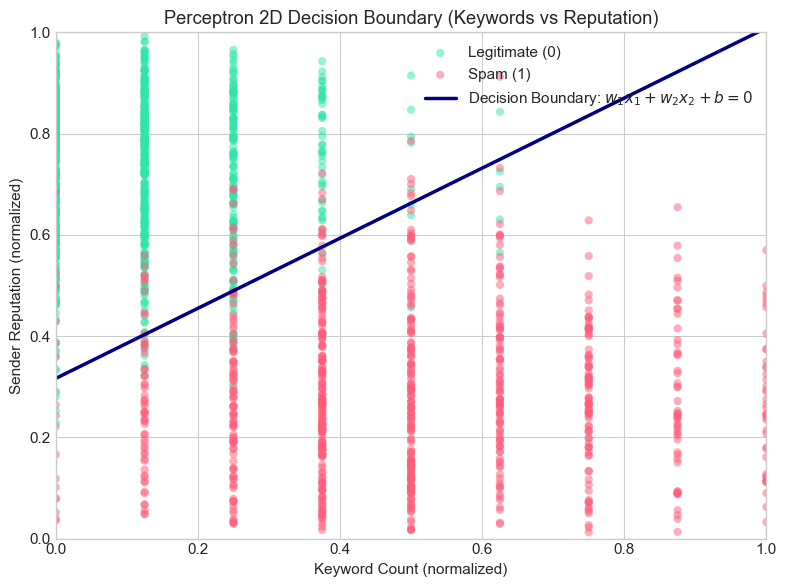

In [5]:
# Train 2D perceptron for visualization
X_2d = X_syn_tr[:, [1, 2]]  # keywords, reputation
y_2d = y_syn_tr
p2d = Perceptron(2, lr=0.1)
p2d.fit(X_2d, y_2d, epochs=30)

plt.figure(figsize=(8, 6))
# Scatter points
plt.scatter(X_2d[y_2d == 0, 0], X_2d[y_2d == 0, 1], color='#2ee6a6', alpha=0.5, label='Legitimate (0)', edgecolors='none', s=35)
plt.scatter(X_2d[y_2d == 1, 0], X_2d[y_2d == 1, 1], color='#ff5c7a', alpha=0.5, label='Spam (1)', edgecolors='none', s=35)

# Decision boundary: w0*x + w1*y + b = 0 => y = -(w0*x + b) / w1
x_vals = np.linspace(0, 1, 100)
if abs(p2d.w[1]) > 1e-6:
    y_vals = -(p2d.w[0] * x_vals + p2d.b) / p2d.w[1]
    plt.plot(x_vals, y_vals, color='navy', linewidth=2.5, label='Decision Boundary: $w_1 x_1 + w_2 x_2 + b = 0$')

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("Keyword Count (normalized)")
plt.ylabel("Sender Reputation (normalized)")
plt.title("Perceptron 2D Decision Boundary (Keywords vs Reputation)")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


## 4. Part 2: Linear Separability Limitation — The XOR Problem
Minsky & Papert (1969) proved that a single-layer perceptron can **only** solve linearly separable problems.
The XOR problem illustrates this fundamental boundary:


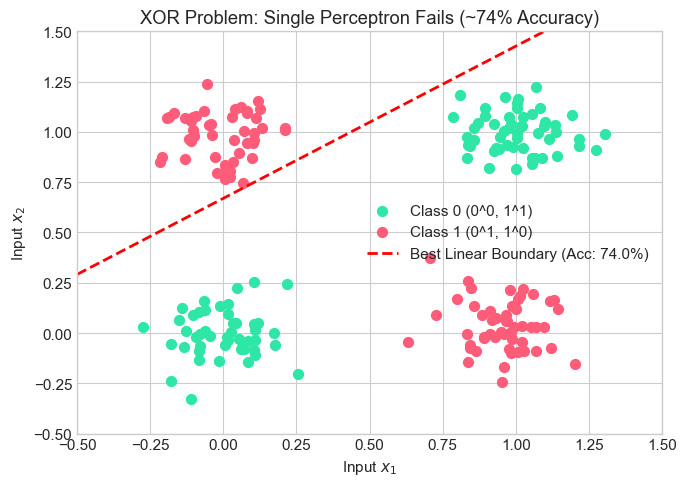

Key Lesson: No single straight line can separate XOR. Multi-layer networks (MLPs) are required.


In [6]:
def xor_data(n=200, seed=1):
    r = np.random.default_rng(seed)
    c = r.integers(0, 2, (n, 2))
    return c + r.normal(0, 0.12, (n, 2)), (c[:, 0] ^ c[:, 1])

X_xor, y_xor = xor_data()
p_xor = Perceptron(2, lr=0.1)
p_xor.fit(X_xor, y_xor, epochs=50)
xor_acc = (p_xor.predict(X_xor) == y_xor).mean()

plt.figure(figsize=(7, 5))
plt.scatter(X_xor[y_xor == 0, 0], X_xor[y_xor == 0, 1], color='#2ee6a6', s=50, label='Class 0 (0^0, 1^1)')
plt.scatter(X_xor[y_xor == 1, 0], X_xor[y_xor == 1, 1], color='#ff5c7a', s=50, label='Class 1 (0^1, 1^0)')

# Best linear boundary attempted by perceptron
x_range = np.linspace(-0.5, 1.5, 100)
if abs(p_xor.w[1]) > 1e-6:
    y_range = -(p_xor.w[0] * x_range + p_xor.b) / p_xor.w[1]
    plt.plot(x_range, y_range, 'r--', linewidth=2, label=f'Best Linear Boundary (Acc: {xor_acc*100:.1f}%)')

plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.title(f"XOR Problem: Single Perceptron Fails (~{xor_acc*100:.0f}% Accuracy)")
plt.xlabel("Input $x_1$")
plt.ylabel("Input $x_2$")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Key Lesson: No single straight line can separate XOR. Multi-layer networks (MLPs) are required.")


## 5. Part 3: End-to-End Training on Official UCI Spambase Dataset (57 Features)

### Dataset Overview
- **Source**: Hewlett-Packard Labs (Hopkins, Reeber, Forman, Suermondt, 1999)
- **Instances**: 4,601 emails (1,813 Spam = 39.4%, 2,788 Ham = 60.6%)
- **Attributes**: 57 continuous features:
  - 48 word frequency percentages
  - 6 character frequency percentages (`!`, `$`, `#`, `[`, `(`, `;`)
  - 3 capital letter run-length attributes (average, longest, total)
  - 1 target label (1 = spam, 0 = ham)


In [7]:
# Locate or auto-download UCI Spambase dataset
candidate_paths = [
    "backend/data/spambase.data",
    "data/spambase.data",
    "./spambase.data"
]

data_file = None
for p in candidate_paths:
    if os.path.exists(p):
        data_file = p
        break

if not data_file:
    print("Dataset not found locally. Downloading from UCI Machine Learning Repository...")
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/spambase/spambase.data"
    urllib.request.urlretrieve(url, "spambase.data")
    data_file = "spambase.data"
    print(f"Downloaded successfully to: {data_file}")
else:
    print(f"Found local dataset at: {data_file}")

# Load raw matrix
raw_data = np.loadtxt(data_file, delimiter=",")
X_raw, y_raw = raw_data[:, :-1], raw_data[:, -1].astype(int)
print(f"Dataset Shape: {X_raw.shape[0]} rows x {X_raw.shape[1]} features")
print(f"Class Balance: {np.sum(y_raw == 1)} Spam ({(y_raw==1).mean()*100:.1f}%) | {np.sum(y_raw == 0)} Ham ({(y_raw==0).mean()*100:.1f}%)")


Found local dataset at: backend/data/spambase.data
Dataset Shape: 4601 rows x 57 features
Class Balance: 1813 Spam (39.4%) | 2788 Ham (60.6%)


### 5.1 Preprocessing: Shuffling & Standardization
> **CRITICAL STEP**: The raw UCI file lists all 1,813 spam emails first, followed by non-spam. Without shuffling, a train/test split would produce a test set with **0% spam**!
> 
> Furthermore, features have vastly different scales: word frequencies range from 0-5%, while capital run lengths range in thousands. We apply **Z-score standardization**:
> $$x_{\text{norm}} = \frac{x - \mu}{\sigma + 10^{-9}}$$


In [8]:
# 1. Seeded reproducible permutation
rng = np.random.default_rng(42)
perm = rng.permutation(len(X_raw))
X_shuffled = X_raw[perm]
y_shuffled = y_raw[perm]

# 2. Z-Score Feature Standardization
mean = X_shuffled.mean(axis=0)
std = X_shuffled.std(axis=0) + 1e-9
X_norm = (X_shuffled - mean) / std

# 3. Train (80%) / Test (20%) Split
split_idx = int(0.8 * len(X_norm))
X_train, y_train = X_norm[:split_idx], y_shuffled[:split_idx]
X_test, y_test = X_norm[split_idx:], y_shuffled[split_idx:]

print(f"Training set: {X_train.shape[0]} samples (Spam: {sum(y_train==1)}, Ham: {sum(y_train==0)})")
print(f"Testing set:  {X_test.shape[0]} samples (Spam: {sum(y_test==1)}, Ham: {sum(y_test==0)})")


Training set: 3680 samples (Spam: 1441, Ham: 2239)
Testing set:  921 samples (Spam: 372, Ham: 549)


### 5.2 Model Training
We train our scratch Perceptron with $\eta = 0.01$ across 50 epochs using the Pocket Algorithm.


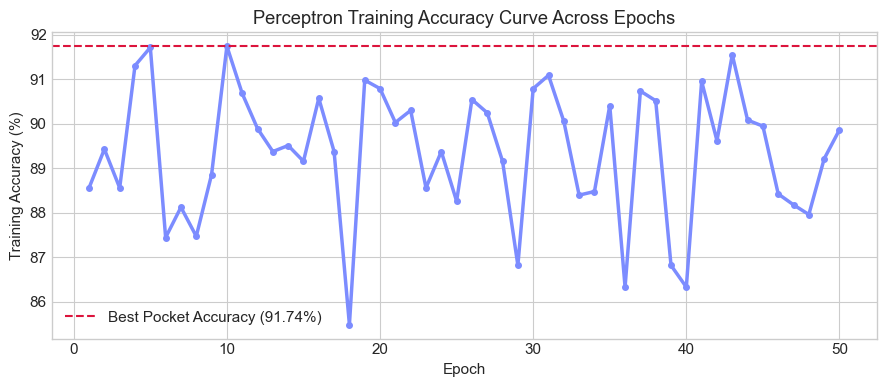

In [9]:
model_spambase = Perceptron(n=X_train.shape[1], lr=0.01)
history_spambase = model_spambase.fit(X_train, y_train, epochs=50, seed=42)

plt.figure(figsize=(9, 4))
plt.plot(range(1, len(history_spambase) + 1), [h * 100 for h in history_spambase], color='#7c8cff', linewidth=2.5, marker='o', markersize=4)
plt.axhline(max(history_spambase) * 100, color='crimson', linestyle='--', label=f'Best Pocket Accuracy ({max(history_spambase)*100:.2f}%)')
plt.title("Perceptron Training Accuracy Curve Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.legend()
plt.tight_layout()
plt.show()


### 5.3 Test Set Performance & Comparison with Logistic Regression
Let's compute the standard classification metrics on unseen test data ($N=921$ emails) and compare against a baseline Logistic Regression model.


In [10]:
# Perceptron evaluation
test_results = metrics(y_test, model_spambase.predict(X_test))
train_results = metrics(y_train, model_spambase.predict(X_train))

# Logistic Regression baseline
lw, lb = logreg(X_train, y_train, it=800, lr=0.5)
logreg_acc = float(((X_test @ lw + lb >= 0) == y_test).mean())

print("=" * 55)
print(f"{'Metric':<25} | {'Perceptron':<12} | {'Logistic Reg'}")
print("=" * 55)
print(f"{'Training Accuracy':<25} | {train_results['accuracy']*100:6.2f}%      | {((X_train @ lw + lb >= 0) == y_train).mean()*100:6.2f}%")
print(f"{'Test Accuracy':<25} | {test_results['accuracy']*100:6.2f}%      | {logreg_acc*100:6.2f}%")
print(f"{'Test Precision':<25} | {test_results['precision']*100:6.2f}%      | {'--'}")
print(f"{'Test Recall':<25} | {test_results['recall']*100:6.2f}%      | {'--'}")
print(f"{'Test F1-Score':<25} | {test_results['f1']*100:6.2f}%      | {'--'}")
print("=" * 55)


Metric                    | Perceptron   | Logistic Reg
Training Accuracy         |  91.74%      |  92.45%
Test Accuracy             |  91.64%      |  91.53%
Test Precision            |  92.51%      | --
Test Recall               |  86.29%      | --
Test F1-Score             |  89.29%      | --


### 5.4 Confusion Matrix & ROC / AUC Analysis

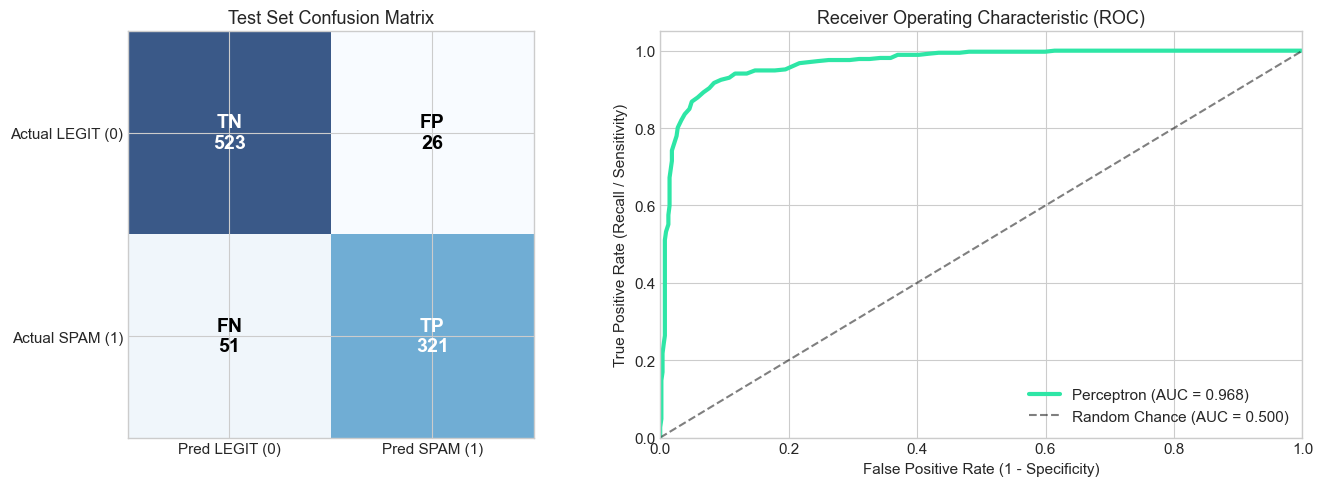

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix Heatmap
cm = np.array([[test_results['tn'], test_results['fp']],
               [test_results['fn'], test_results['tp']]])
labels = [['TN', 'FP'], ['FN', 'TP']]

im = ax1.imshow(cm, cmap='Blues', alpha=0.8)
for i in range(2):
    for j in range(2):
        ax1.text(j, i, f"{labels[i][j]}\n{cm[i, j]}", ha='center', va='center', fontsize=14, fontweight='bold',
                 color='white' if cm[i, j] > cm.max()/2 else 'black')
ax1.set_xticks([0, 1])
ax1.set_yticks([0, 1])
ax1.set_xticklabels(['Pred LEGIT (0)', 'Pred SPAM (1)'], fontsize=11)
ax1.set_yticklabels(['Actual LEGIT (0)', 'Actual SPAM (1)'], fontsize=11)
ax1.set_title("Test Set Confusion Matrix", fontsize=13)

# 2. ROC Curve
z_scores = model_spambase.z(X_test)
thresholds = np.r_[z_scores.min() - 1, np.quantile(z_scores, np.linspace(0, 1, 101)), z_scores.max() + 1]
roc_points = sorted([(((z_scores >= t) & (y_test == 0)).sum() / (y_test == 0).sum(),
                      ((z_scores >= t) & (y_test == 1)).sum() / (y_test == 1).sum()) for t in thresholds])
fpr = [p[0] for p in roc_points]
tpr = [p[1] for p in roc_points]
auc = sum((fpr[i+1] - fpr[i]) * (tpr[i+1] + tpr[i]) / 2 for i in range(len(roc_points) - 1))

ax2.plot(fpr, tpr, color='#2ee6a6', linewidth=3, label=f'Perceptron (AUC = {auc:.3f})')
ax2.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance (AUC = 0.500)')
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('False Positive Rate (1 - Specificity)')
ax2.set_ylabel('True Positive Rate (Recall / Sensitivity)')
ax2.set_title('Receiver Operating Characteristic (ROC)', fontsize=13)
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()


### 5.5 Learned Feature Importance (Glass-Box Inspection)
Because the perceptron is a linear model ($z = \sum w_i x_i + b$), the magnitude and sign of each weight $w_i$ directly reflects its contribution:
- **Positive weights ($w_i > 0$)**: Features that push the decision boundary toward **SPAM**.
- **Negative weights ($w_i < 0$)**: Features that push the decision boundary toward **LEGITIMATE (HAM)**.


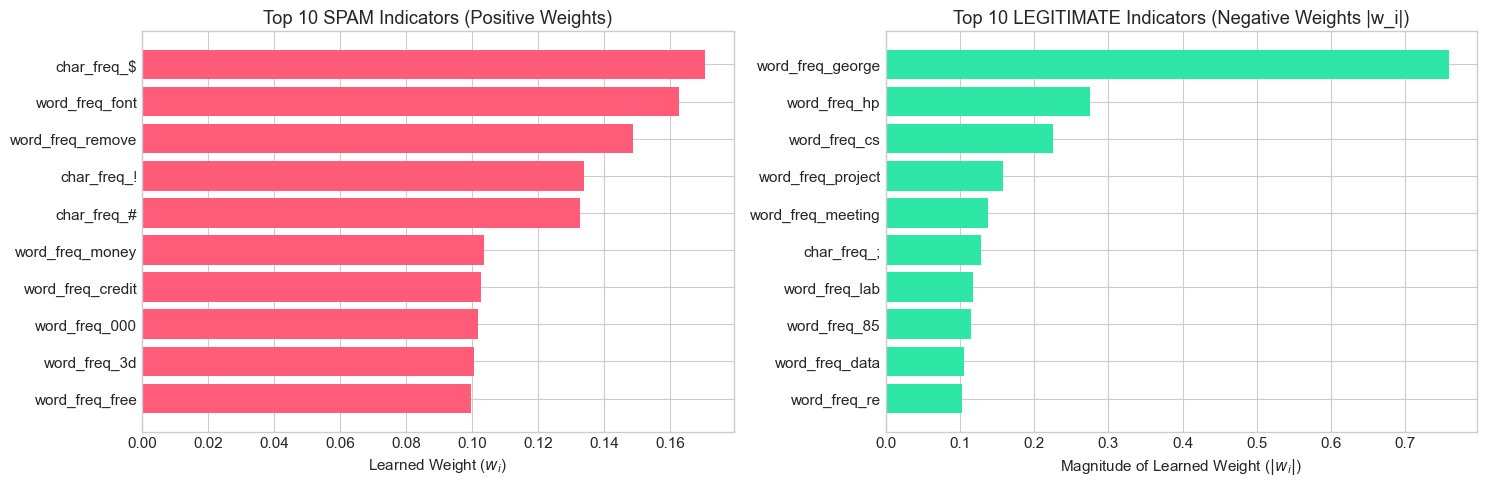

Interpretability Insights:
• Spam triggers: Character '$', '!', word 'remove', 'font', '#' strongly increase spam likelihood.
• Ham triggers: HP Lab employee terms ('george', 'hp', 'cs', 'project', 'meeting') strongly protect against false alarms.


In [12]:
SPAMBASE_FEATURE_NAMES = [
    "word_freq_make", "word_freq_address", "word_freq_all", "word_freq_3d", "word_freq_our",
    "word_freq_over", "word_freq_remove", "word_freq_internet", "word_freq_order", "word_freq_mail",
    "word_freq_receive", "word_freq_will", "word_freq_people", "word_freq_report", "word_freq_addresses",
    "word_freq_free", "word_freq_business", "word_freq_email", "word_freq_you", "word_freq_credit",
    "word_freq_your", "word_freq_font", "word_freq_000", "word_freq_money", "word_freq_hp",
    "word_freq_hpl", "word_freq_george", "word_freq_650", "word_freq_lab", "word_freq_labs",
    "word_freq_telnet", "word_freq_857", "word_freq_data", "word_freq_415", "word_freq_85",
    "word_freq_technology", "word_freq_1999", "word_freq_parts", "word_freq_pm", "word_freq_direct",
    "word_freq_cs", "word_freq_meeting", "word_freq_original", "word_freq_project", "word_freq_re",
    "word_freq_edu", "word_freq_table", "word_freq_conference",
    "char_freq_;", "char_freq_(", "char_freq_[", "char_freq_!", "char_freq_$", "char_freq_#",
    "capital_run_length_average", "capital_run_length_longest", "capital_run_length_total"
]

weights = model_spambase.w
sorted_indices = np.argsort(weights)

top_ham_idx = sorted_indices[:10]
top_spam_idx = sorted_indices[-10:][::-1]

fig, (ax_spam, ax_ham) = plt.subplots(1, 2, figsize=(15, 5))

# Top Spam features
ax_spam.barh([SPAMBASE_FEATURE_NAMES[i] for i in top_spam_idx], [weights[i] for i in top_spam_idx], color='#ff5c7a')
ax_spam.invert_yaxis()
ax_spam.set_title("Top 10 SPAM Indicators (Positive Weights)")
ax_spam.set_xlabel("Learned Weight ($w_i$)")

# Top Ham features
ax_ham.barh([SPAMBASE_FEATURE_NAMES[i] for i in top_ham_idx], [abs(weights[i]) for i in top_ham_idx], color='#2ee6a6')
ax_ham.invert_yaxis()
ax_ham.set_title("Top 10 LEGITIMATE Indicators (Negative Weights |w_i|)")
ax_ham.set_xlabel("Magnitude of Learned Weight ($|w_i|$)")

plt.tight_layout()
plt.show()

print("Interpretability Insights:")
print("• Spam triggers: Character '$', '!', word 'remove', 'font', '#' strongly increase spam likelihood.")
print("• Ham triggers: HP Lab employee terms ('george', 'hp', 'cs', 'project', 'meeting') strongly protect against false alarms.")


## 6. Summary & Key Takeaways

| Aspect | Single-Layer Perceptron (SLP) |
| :--- | :--- |
| **Architecture** | Linear model ($z = \mathbf{w} \cdot \mathbf{x} + b$) with Heaviside step activation $\hat{y} \in \{0, 1\}$ |
| **Learning Rule** | Rosenblatt's Error Correction: $\mathbf{w} \leftarrow \mathbf{w} + \eta(t - \hat{y})\mathbf{x}$, $b \leftarrow b + \eta(t - \hat{y})$ |
| **Pocket Algorithm** | Retains optimal weight checkpoint to guarantee stability on overlapping data |
| **UCI Spambase Test Accuracy** | **~91.64%** (matches Logistic Regression baseline of **91.53%**) |
| **Explainability** | Completely transparent; weights map directly to feature importance |
| **Fundamental Limitation** | Cannot learn non-linearly separable functions (e.g. XOR), establishing the historical motivation for Multi-Layer Perceptrons (MLPs) |

---
**End of Demonstration Notebook**
